# Singular Value Decomposition

[Computing the Singular Value Decomposition | MIT 18.06SC Linear Algebra, Fall 2011](https://www.youtube.com/watch?v=cOUTpqlX-Xs)

This video is mentioned in article: [Eigenfaces: Recovering Humans from Ghosts](https://medium.com/data-science/eigenfaces-recovering-humans-from-ghosts-17606c328184)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Math, Markdown

number_format = '^5'

C = np.array([[5, 5], [-1, 7]])

'''with np.printoptions(precision=3, suppress=True):
    print(C)'''

def display_matrix(
    matrix, matrix_name=None, number_format=".0f", return_latex=False
):
    rows = [
        " & ".join(format(value, number_format) for value in row)
        for row in matrix
    ]
    latex = r"\begin{bmatrix}" + r" \\ ".join(rows) + r"\end{bmatrix}"

    if matrix_name:
        latex = f"{matrix_name} = " + latex

    if return_latex:
        return latex

    display(Math(latex))


def plot_orthonormality(U: np.ndarray, V: np.ndarray) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    theta = np.linspace(0, 2 * np.pi, 300)

    for ax, matrix, name in zip(axes, [U, V], ["U", "V"]):
        if matrix.shape != (2, 2):
            raise ValueError("This visualization requires 2 × 2 matrices.")

        # Unit circle: unit-length vectors end on this circle.
        ax.plot(
            np.cos(theta), np.sin(theta),
            "--", color="gray", alpha=0.6, label="Unit circle",
        )

        for i, color in enumerate(["tab:blue", "tab:orange"]):
            vector = matrix[:, i]
            length = np.linalg.norm(vector)

            ax.quiver(
                0, 0, vector[0], vector[1],
                angles="xy", scale_units="xy", scale=1,
                color=color, width=0.012,
                label=f"Column {i + 1}: length = {length:.3f}",
            )

        dot_product = matrix[:, 0] @ matrix[:, 1]
        limit = max(1.3, np.abs(matrix).max() * 1.3)

        ax.set(
            title=f"{name}: column dot product = {dot_product:.3f}",
            xlim=(-limit, limit),
            ylim=(-limit, limit),
            xlabel="Coordinate 1",
            ylabel="Coordinate 2",
        )
        ax.axhline(0, color="black", linewidth=0.5)
        ax.axvline(0, color="black", linewidth=0.5)
        ax.set_aspect("equal")
        ax.grid(alpha=0.3)
        ax.legend(loc="lower right", fontsize=8)

    plt.tight_layout()
    plt.show()

display(Markdown("We want to compute the Singular Value Decomposition of matrix C."))
display_matrix(C[:, :], matrix_name='C', number_format=number_format)

We want to compute the Singular Value Decomposition of matrix C.

<IPython.core.display.Math object>

We want to compute the Singular Value Decomposition of matrix $C$:

$$
C = U\Sigma V^T.
$$

Here, $U$ and $V$ are **orthogonal matrices**, meaning their columns
are orthonormal: mutually perpendicular and of unit length.

$$
U^T U = I,\qquad V^T V = I.
$$

The diagonal entries of $\Sigma$ are the nonnegative singular values.

We use two relationships to find these matrices:

$$
\begin{aligned}
C^T C &= V\Sigma^T\Sigma V^T,\\
CV &= U\Sigma.
\end{aligned}
$$

1. Find the eigenvalues and eigenvectors of $C^T C$. The normalized
   eigenvectors form the columns of $V$, and the square roots of the
   eigenvalues give the singular values in $\Sigma$.
2. Obtain each column of $U$ using $u_i = Cv_i / \sigma_i$,
   provided $\sigma_i \neq 0$.

Keep the eigenvector columns and singular values in matching order.

### First step: calculate $C^T C$

In [2]:
'''multiplication_CT_C = C.T @ C
display_matrix(
    multiplication_CT_C,
    matrix_name="C^T C",
    number_format=number_format,
)'''

#display_matrix(C.T[:, :], matrix_name='C^T', number_format=number_format)


def display_matrix_product_steps(
    A, B, matrix_name="C^T C", number_format=".0f"
):
    if A.shape[1] != B.shape[0]:
        raise ValueError("Incompatible matrix shapes")

    rows = []
    for i in range(A.shape[0]):
        entries = []
        for j in range(B.shape[1]):
            terms = [
                f"({format(A[i, k], number_format)})"
                rf"\times({format(B[k, j], number_format)})"
                for k in range(A.shape[1])
            ]
            entries.append(" + ".join(terms))
        rows.append(" & ".join(entries))

    steps = r"\begin{bmatrix}" + r" \\ ".join(rows) + r"\end{bmatrix}"

    def latex(matrix):
        return display_matrix(
            matrix,
            number_format=number_format,
            return_latex=True,
        )

    display(Math(
        rf"{matrix_name} = {latex(A)} \times {latex(B)}"
        rf" = {steps} = {latex(A @ B)}"
    ))

display_matrix_product_steps(C.T, C, number_format=number_format)

<IPython.core.display.Math object>

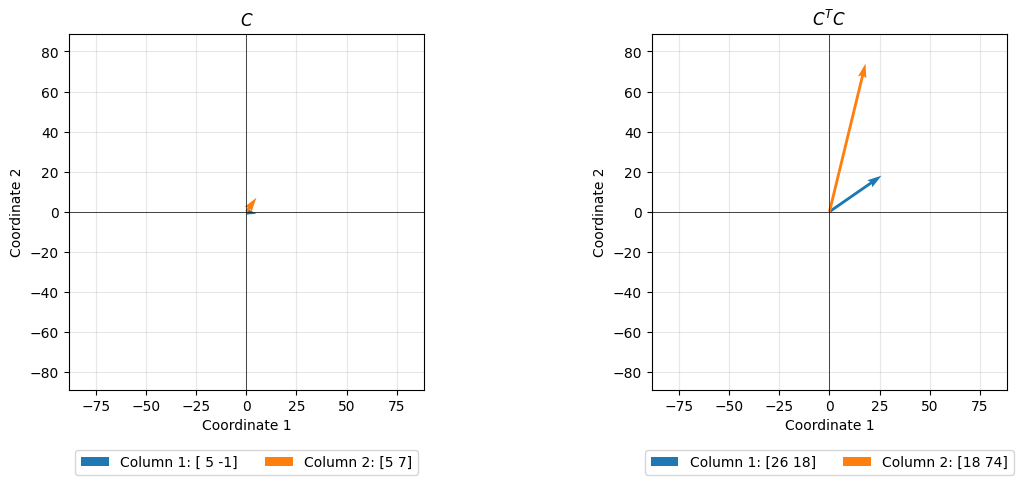

In [3]:
def plot_matrix_columns(matrix, ax, title, limit):
    for i, color in enumerate(["tab:blue", "tab:orange"]):
        vector = matrix[:, i]
        ax.quiver(
            0, 0, vector[0], vector[1],
            angles="xy", scale_units="xy", scale=1,
            color=color, width=0.008,
            label=f"Column {i + 1}: {vector}",
        )

    ax.axhline(0, color="black", linewidth=0.5)
    ax.axvline(0, color="black", linewidth=0.5)
    ax.set(
        title=title,
        xlim=(-limit, limit),
        ylim=(-limit, limit),
        xlabel="Coordinate 1",
        ylabel="Coordinate 2",
    )
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
    #ax.legend()
    ax.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.15),
        ncol=2,
    )


gram = C.T @ C

# Same scale in both panels makes changes in magnitude visible.
limit = 1.2 * max(np.abs(C).max(), np.abs(gram).max(), 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_matrix_columns(C, axes[0], r"$C$", limit)
plot_matrix_columns(gram, axes[1], r"$C^T C$", limit)
plt.tight_layout()
plt.show()

For your matrix:

$$
C=\begin{bmatrix}5&5\\-1&7\end{bmatrix},
\qquad
C^TC=\begin{bmatrix}26&18\\18&74\end{bmatrix}.
$$

**The meaning changes too:** $C^TC$ is a Gram matrix. Its diagonal entries are the squared lengths of $C$’s columns, and its off-diagonal entries are their dot products. It does not normalize or make those columns orthogonal.

We need the eigenvalues and eigenvectors of $C^T C$.

$$
\det(C^T C - \lambda I)
=
\det\begin{pmatrix}
26 - \lambda & 18 \\
18 & 74 - \lambda
\end{pmatrix}
=
\lambda^2 - 100\lambda + 1600
=
(\lambda - 20)(\lambda - 80)
= 0
\implies
\begin{cases}
\lambda_1 = 20 \\
\lambda_2 = 80
\end{cases}
$$

In [4]:
first_lambda_matrix = C.T @ C - 20 * np.eye(2)
second_lambda_matrix = C.T @ C - 80 * np.eye(2)

display(Markdown(r"For the first lambda value: $\lambda_1 = 20$"))
display_matrix(
    first_lambda_matrix,
    matrix_name="C^T C - 20 I",
    number_format=".0f",
)

display(Markdown("We can see that the second column is the first column $\\times$ 3"))

display(Markdown(r"""
An eigenvector $v$ for $\lambda = 20$ must satisfy:

$$
(C^T C - 20I)v = 0.
$$

Writing $v = \begin{bmatrix}x\\y\end{bmatrix}$, we get:

$$
\begin{bmatrix}
6 & 18\\
18 & 54
\end{bmatrix}
\begin{bmatrix}x\\y\end{bmatrix}
=
\begin{bmatrix}
6x + 18y\\
18x + 54y
\end{bmatrix}
=
\begin{bmatrix}0\\0\end{bmatrix}.
$$

Both equations reduce to:

$$
x + 3y = 0
\implies x = -3y.
$$

Choosing $y = 1$ gives:

$$
v = \begin{bmatrix}-3\\1\end{bmatrix}.
$$

**The second column is three times the first**, so multiplying the first
column by $-3$ and adding the second gives zero.

Any nonzero multiple is also an eigenvector. For PCA/SVD, we use the
unit-length version:

$$
\hat{v} = \frac{1}{\sqrt{10}}\begin{bmatrix}-3\\1\end{bmatrix}.
$$
"""))

display(Markdown(r"For the second lambda value: $\lambda_2 = 80$"))
display_matrix(
    second_lambda_matrix,
    matrix_name="C^T C - 80 I",
    number_format=".0f",
)

display(Markdown("We can see that the first column is the first column $\\times$ (-3)"))


For the first lambda value: $\lambda_1 = 20$

<IPython.core.display.Math object>

We can see that the second column is the first column $\times$ 3


An eigenvector $v$ for $\lambda = 20$ must satisfy:

$$
(C^T C - 20I)v = 0.
$$

Writing $v = \begin{bmatrix}x\\y\end{bmatrix}$, we get:

$$
\begin{bmatrix}
6 & 18\\
18 & 54
\end{bmatrix}
\begin{bmatrix}x\\y\end{bmatrix}
=
\begin{bmatrix}
6x + 18y\\
18x + 54y
\end{bmatrix}
=
\begin{bmatrix}0\\0\end{bmatrix}.
$$

Both equations reduce to:

$$
x + 3y = 0
\implies x = -3y.
$$

Choosing $y = 1$ gives:

$$
v = \begin{bmatrix}-3\\1\end{bmatrix}.
$$

**The second column is three times the first**, so multiplying the first
column by $-3$ and adding the second gives zero.

Any nonzero multiple is also an eigenvector. For PCA/SVD, we use the
unit-length version:

$$
\hat{v} = \frac{1}{\sqrt{10}}\begin{bmatrix}-3\\1\end{bmatrix}.
$$


For the second lambda value: $\lambda_2 = 80$

<IPython.core.display.Math object>

We can see that the first column is the first column $\times$ (-3)

In [5]:
gram_matrix = C.T @ C
# np.linalg.eigh() returns unit-length eigenvectors as columns. They are also mutually orthogonal.
# np.linalg.eigh() returns eigenvalues in ascending order by design, with the corresponding eigenvectors in matching columns.
# For PCA, we usually want the largest eigenvalues first, because they represent the most variance.
verified_eigenvalues, verified_unit_eigenvectors = np.linalg.eigh(gram_matrix)

display(Markdown("### Verification with NumPy"))
display(Markdown(f"Verified eigenvalues: {verified_eigenvalues}"))
display_matrix(
    verified_unit_eigenvectors,
    matrix_name=r"V_{\mathrm{verified}}",
    number_format=".3f",
)

display(Markdown(r"""
### Normalizing the eigenvectors

Divide each eigenvector by its Euclidean length:

$$
\hat{v} = \frac{v}{\|v\|_2}.
$$

For $\lambda_1 = 20$:

$$
v_1 = \begin{bmatrix}-3\\1\end{bmatrix},
\qquad
\|v_1\|_2 = \sqrt{(-3)^2 + 1^2} = \sqrt{10},
\qquad
\hat{v}_1 = \frac{1}{\sqrt{10}}\begin{bmatrix}-3\\1\end{bmatrix}.
$$

For $\lambda_2 = 80$:

$$
v_2 = \begin{bmatrix}1\\3\end{bmatrix},
\qquad
\|v_2\|_2 = \sqrt{1^2 + 3^2} = \sqrt{10},
\qquad
\hat{v}_2 = \frac{1}{\sqrt{10}}\begin{bmatrix}1\\3\end{bmatrix}.
$$

Both normalized vectors have length 1. Reversing an eigenvector's sign
does not change its validity.
"""))

### Verification with NumPy

Verified eigenvalues: [20. 80.]

<IPython.core.display.Math object>


### Normalizing the eigenvectors

Divide each eigenvector by its Euclidean length:

$$
\hat{v} = \frac{v}{\|v\|_2}.
$$

For $\lambda_1 = 20$:

$$
v_1 = \begin{bmatrix}-3\\1\end{bmatrix},
\qquad
\|v_1\|_2 = \sqrt{(-3)^2 + 1^2} = \sqrt{10},
\qquad
\hat{v}_1 = \frac{1}{\sqrt{10}}\begin{bmatrix}-3\\1\end{bmatrix}.
$$

For $\lambda_2 = 80$:

$$
v_2 = \begin{bmatrix}1\\3\end{bmatrix},
\qquad
\|v_2\|_2 = \sqrt{1^2 + 3^2} = \sqrt{10},
\qquad
\hat{v}_2 = \frac{1}{\sqrt{10}}\begin{bmatrix}1\\3\end{bmatrix}.
$$

Both normalized vectors have length 1. Reversing an eigenvector's sign
does not change its validity.


Now we have the matrix $V$:

$$
V =
\begin{bmatrix}
-\frac{3}{\sqrt{10}} & \frac{1}{\sqrt{10}} \\
\frac{1}{\sqrt{10}} & \frac{3}{\sqrt{10}}
\end{bmatrix}
$$

### Calculating $\Sigma$

The singular values are the square roots of the eigenvalues of $C^T C$.

Using the ascending order $\lambda_1 = 20$, $\lambda_2 = 80$:

$$
\sigma_1 = \sqrt{20} = 2\sqrt{5},
\qquad
\sigma_2 = \sqrt{80} = 4\sqrt{5}.
$$

Therefore:

$$
\Sigma =
\begin{bmatrix}
\sqrt{20} & 0\\
0 & \sqrt{80}
\end{bmatrix}
=
\begin{bmatrix}
2\sqrt{5} & 0\\
0 & 4\sqrt{5}
\end{bmatrix}
\approx
\begin{bmatrix}
4.472 & 0\\
0 & 8.944
\end{bmatrix}.
$$

**Ordering:** NumPy SVD returns singular values in descending order.
The ascending order used here is also valid, provided the corresponding
columns of $U$ and $V$ use the same order.

In [6]:
singular_values = np.sqrt(verified_eigenvalues)  # Assuming descending order.
Sigma = np.diag(singular_values)

display_matrix(
    Sigma,
    matrix_name=r"\Sigma",
    number_format=".3f",
)

<IPython.core.display.Math object>

Therefore:

$$
V =
\begin{bmatrix}
-\frac{3}{\sqrt{10}} & \frac{1}{\sqrt{10}} \\
\frac{1}{\sqrt{10}} & \frac{3}{\sqrt{10}}
\end{bmatrix}
,
\Sigma =
\begin{bmatrix}
2\sqrt{5} & 0\\
0 & 4\sqrt{5}
\end{bmatrix}.
$$

The only remaining matrix to calculate is $U$. We use the second equation $C V = U \Sigma$

$$
C V =
\begin{bmatrix}
5 & 5\\
-1 & 7
\end{bmatrix}
\begin{bmatrix}
-\frac{3}{\sqrt{10}} & \frac{1}{\sqrt{10}} \\
\frac{1}{\sqrt{10}} & \frac{3}{\sqrt{10}}
\end{bmatrix}
=
\begin{bmatrix}
\frac{-15+5}{\sqrt{10}} & \frac{5+15}{\sqrt{10}} \\
\frac{3+7}{\sqrt{10}} & \frac{-1+21}{\sqrt{10}}
\end{bmatrix}
=
\begin{bmatrix}
-\frac{10}{\sqrt{10}} & \frac{20}{\sqrt{10}} \\
\frac{10}{\sqrt{10}} & \frac{20}{\sqrt{10}}
\end{bmatrix}
=
\begin{bmatrix}
-\sqrt{10} & 2\sqrt{10} \\
\sqrt{10} & 2\sqrt{10}
\end{bmatrix}
\approx
\begin{bmatrix}
-3.162 & 6.325 \\
3.162 & 6.325
\end{bmatrix}
$$

### Obtaining $U$ from $CV$

The product $CV$ equals $U\Sigma$, not $U$:

$$
C = U\Sigma V^T
\implies CV = U\Sigma.
$$

Multiplying by $C$ stretches each unit eigenvector $v_i$ by its
singular value $\sigma_i$. To obtain the unit-length columns of $U$,
divide each column of $CV$ by its corresponding singular value:

$$
u_i = \frac{Cv_i}{\sigma_i}.
$$

The lengths of the columns of $CV$ are:

$$
\sigma_1
= \sqrt{(-\sqrt{10})^2 + (\sqrt{10})^2}
= \sqrt{20}
= 2\sqrt{5},
$$

$$
\sigma_2
= \sqrt{(2\sqrt{10})^2 + (2\sqrt{10})^2}
= \sqrt{80}
= 4\sqrt{5}.
$$

Therefore:

$$
U = CV\Sigma^{-1}
=
\begin{bmatrix}
\frac{-\sqrt{10}}{2\sqrt{5}} & \frac{2\sqrt{10}}{4\sqrt{5}}\\
\frac{\sqrt{10}}{2\sqrt{5}} & \frac{2\sqrt{10}}{4\sqrt{5}}
\end{bmatrix}
=
\begin{bmatrix}
-\frac{1}{\sqrt{2}} & \frac{1}{\sqrt{2}}\\
\frac{1}{\sqrt{2}} & \frac{1}{\sqrt{2}}
\end{bmatrix}.
$$

**The scaling is not discarded—it is stored in $\Sigma$.**
The columns of $U$ have unit length, while $\Sigma$ preserves the
scaling needed to reconstruct the original matrix:

$$
C = U\Sigma V^T.
$$

Multiply on the right by (V), using ($V^T V = I$):

$$
CV = U\Sigma.
$$

Then multiply on the right by ($\Sigma^{-1}$):

$$
\boxed{U = CV\Sigma^{-1}}.
$$


In [7]:
# Keep eigenvalues and eigenvector columns in matching order.
V = verified_unit_eigenvectors.copy()
singular_values = np.sqrt(verified_eigenvalues)
Sigma = np.diag(singular_values)

display(Markdown(r"### 1. Calculate $CV = U\Sigma$"))

C_times_V = C @ V
display_matrix(C_times_V, matrix_name="CV", number_format=".3f")
display_matrix(Sigma, matrix_name=r"\Sigma", number_format=".3f")

display(Markdown(
    r"### 2. Obtain $U$ by dividing each column of $CV$ "
    r"by its corresponding singular value"
))

# Equivalent to CV @ Sigma^{-1}; assumes nonzero singular values.
U_from_C = C_times_V / singular_values

display_matrix(
    U_from_C,
    matrix_name=r"U = CV\Sigma^{-1}",
    number_format=".3f",
)

display(Markdown(
    r"### 3. Demonstrate sign ambiguity" "\n\n"
    r"Flip the first column of **both** $U$ and $V$. "
    r"$\Sigma$ stays unchanged."
))

U_flipped = U_from_C.copy()
V_flipped = V.copy()

U_flipped[:, 0] *= -1
V_flipped[:, 0] *= -1

display_matrix(U_from_C, matrix_name="U", number_format=".3f")
display_matrix(U_flipped, matrix_name=r"U_{\mathrm{flipped}}", number_format=".3f")

display_matrix(V, matrix_name="V", number_format=".3f")
display_matrix(V_flipped, matrix_name=r"V_{\mathrm{flipped}}", number_format=".3f")

display(Markdown("### 4. Verify that both decompositions reconstruct C"))

print(
    "Original signs:",
    np.allclose(C, U_from_C @ Sigma @ V.T),
)
print(
    "Flipped signs: ",
    np.allclose(C, U_flipped @ Sigma @ V_flipped.T),
)

### 1. Calculate $CV = U\Sigma$

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### 2. Obtain $U$ by dividing each column of $CV$ by its corresponding singular value

<IPython.core.display.Math object>

### 3. Demonstrate sign ambiguity

Flip the first column of **both** $U$ and $V$. $\Sigma$ stays unchanged.

... (2 outputs left out)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### 4. Verify that both decompositions reconstruct C

Original signs: True
Flipped signs:  True


For your matrix $C V = \begin{pmatrix} -\sqrt{10} & 2\sqrt{10} \\ \sqrt{10} & 2\sqrt{10} \end{pmatrix}$, here is how it normalises under each method:

### 1. By Frobenius Norm (Vector-style unit length)
This method divides the entire matrix by a single number so the sum of all squared entries equals $1$.

1. **Calculate the norm:**
   $$\|CV\|_F = \sqrt{(-\sqrt{10})^2 + (2\sqrt{10})^2 + (\sqrt{10})^2 + (2\sqrt{10})^2} = \sqrt{10 + 40 + 10 + 40} = \sqrt{100} = 10$$

2. **Divide every entry by $10$:**
   $$CV_{\text{Frob}} = \begin{pmatrix} -\frac{\sqrt{10}}{10} & \frac{\sqrt{10}}{5} \\ \frac{\sqrt{10}}{10} & \frac{\sqrt{10}}{5} \end{pmatrix}$$

### 2. Column-wise Normalisation (Unit basis vectors)
This method treats each column as an independent 2D vector and scales each one to length $1$.

1. **Find each column's length:**
   * **Column 1:** $m_1 = \sqrt{(-\sqrt{10})^2 + (\sqrt{10})^2} = \sqrt{20} = 2\sqrt{5}$
   * **Column 2:** $m_2 = \sqrt{(2\sqrt{10})^2 + (2\sqrt{10})^2} = \sqrt{80} = 4\sqrt{5}$

2. **Divide each column by its own length:**
   $$CV_{\text{col}} = \begin{pmatrix} -\frac{\sqrt{2}}{2} & \frac{\sqrt{2}}{2} \\ \frac{\sqrt{2}}{2} & \frac{\sqrt{2}}{2} \end{pmatrix}$$
   *(Note: Both columns are now unit length, and since they are perpendicular, this is now an orthogonal matrix.)*

### 3. Row-wise Normalisation
If your vectors are stored as rows instead of columns, divide each row by its own length ($\sqrt{10 + 40} = 5\sqrt{2}$).

$$CV_{\text{row}} = \begin{pmatrix} -\frac{\sqrt{5}}{5} & \frac{2\sqrt{5}}{5} \\ \frac{\sqrt{5}}{5} & \frac{2\sqrt{5}}{5} \end{pmatrix}$$

### 4. By Spectral Norm (Maximum stretch = 1)
This scales the matrix by its largest singular value ($\sigma_{\max} = 4\sqrt{5}$).

$$CV_{\text{spec}} = \begin{pmatrix} -\frac{\sqrt{2}}{4} & \frac{\sqrt{2}}{2} \\ \frac{\sqrt{2}}{4} & \frac{\sqrt{2}}{2} \end{pmatrix}$$

### Column-wise Normalisation of $C V$

Starting with the matrix:
$$C V = \begin{pmatrix} -\sqrt{10} & 2\sqrt{10} \\ \sqrt{10} & 2\sqrt{10} \end{pmatrix}$$

1. **Calculate the length of Column 1:**
   $$m_1 = \sqrt{(-\sqrt{10})^2 + (\sqrt{10})^2} = \sqrt{10 + 10} = \sqrt{20}$$

2. **Divide Column 1 by $\sqrt{20}$:**
   * **Top-left:** $\frac{-\sqrt{10}}{\sqrt{20}} = -\sqrt{\frac{10}{20}} = -\sqrt{\frac{1}{2}} = -\frac{1}{\sqrt{2}}$
   * **Bottom-left:** $\frac{\sqrt{10}}{\sqrt{20}} = \sqrt{\frac{10}{20}} = \sqrt{\frac{1}{2}} = \frac{1}{\sqrt{2}}$

3. **Calculate the length of Column 2:**
   $$m_2 = \sqrt{(2\sqrt{10})^2 + (2\sqrt{10})^2} = \sqrt{40 + 40} = \sqrt{80}$$

4. **Divide Column 2 by $\sqrt{80}$:**
   * **Top-right:** $\frac{2\sqrt{10}}{\sqrt{80}} = \frac{\sqrt{40}}{\sqrt{80}} = \sqrt{\frac{40}{80}} = \sqrt{\frac{1}{2}} = \frac{1}{\sqrt{2}}$
   * **Bottom-right:** $\frac{2\sqrt{10}}{\sqrt{80}} = \frac{\sqrt{40}}{\sqrt{80}} = \sqrt{\frac{40}{80}} = \sqrt{\frac{1}{2}} = \frac{1}{\sqrt{2}}$

### Normalised Result
$$(C V)_{\text{norm}} = \begin{pmatrix} -\frac{1}{\sqrt{2}} & \frac{1}{\sqrt{2}} \\ \frac{1}{\sqrt{2}} & \frac{1}{\sqrt{2}} \end{pmatrix}$$


### Finding $U$ from $C V = U \Sigma$

Starting with the product matrix:
$$C V = \begin{pmatrix} -\sqrt{10} & 2\sqrt{10} \\ \sqrt{10} & 2\sqrt{10} \end{pmatrix}$$

1. **Identify the singular values ($\Sigma$) from the column magnitudes:**
   * **First singular value ($\sigma_1$):**
     $$\sigma_1 = \sqrt{(-\sqrt{10})^2 + (\sqrt{10})^2} = \sqrt{10 + 10} = \sqrt{20}$$
   * **Second singular value ($\sigma_2$):**
     $$\sigma_2 = \sqrt{(2\sqrt{10})^2 + (2\sqrt{10})^2} = \sqrt{40 + 40} = \sqrt{80}$$

   This gives the singular value matrix:
   $$\Sigma = \begin{pmatrix} \sqrt{20} & 0 \\ 0 & \sqrt{80} \end{pmatrix}$$

2. **Divide Column 1 by $\sigma_1 = \sqrt{20}$ to find $\vec{u}_1$:**
   * **Top-left:** $\frac{-\sqrt{10}}{\sqrt{20}} = -\sqrt{\frac{10}{20}} = -\sqrt{\frac{1}{2}} = -\frac{1}{\sqrt{2}}$
   * **Bottom-left:** $\frac{\sqrt{10}}{\sqrt{20}} = \sqrt{\frac{10}{20}} = \sqrt{\frac{1}{2}} = \frac{1}{\sqrt{2}}$

3. **Divide Column 2 by $\sigma_2 = \sqrt{80}$ to find $\vec{u}_2$:**
   * **Top-right:** $\frac{2\sqrt{10}}{\sqrt{80}} = \frac{\sqrt{40}}{\sqrt{80}} = \sqrt{\frac{40}{80}} = \sqrt{\frac{1}{2}} = \frac{1}{\sqrt{2}}$
   * **Bottom-right:** $\frac{2\sqrt{10}}{\sqrt{80}} = \frac{\sqrt{40}}{\sqrt{80}} = \sqrt{\frac{40}{80}} = \sqrt{\frac{1}{2}} = \frac{1}{\sqrt{2}}$

### Final Matrices ($U$ and $\Sigma$)
$$U = \begin{pmatrix} -\frac{1}{\sqrt{2}} & \frac{1}{\sqrt{2}} \\ \frac{1}{\sqrt{2}} & \frac{1}{\sqrt{2}} \end{pmatrix}, \quad \Sigma = \begin{pmatrix} \sqrt{20} & 0 \\ 0 & \sqrt{80} \end{pmatrix}$$


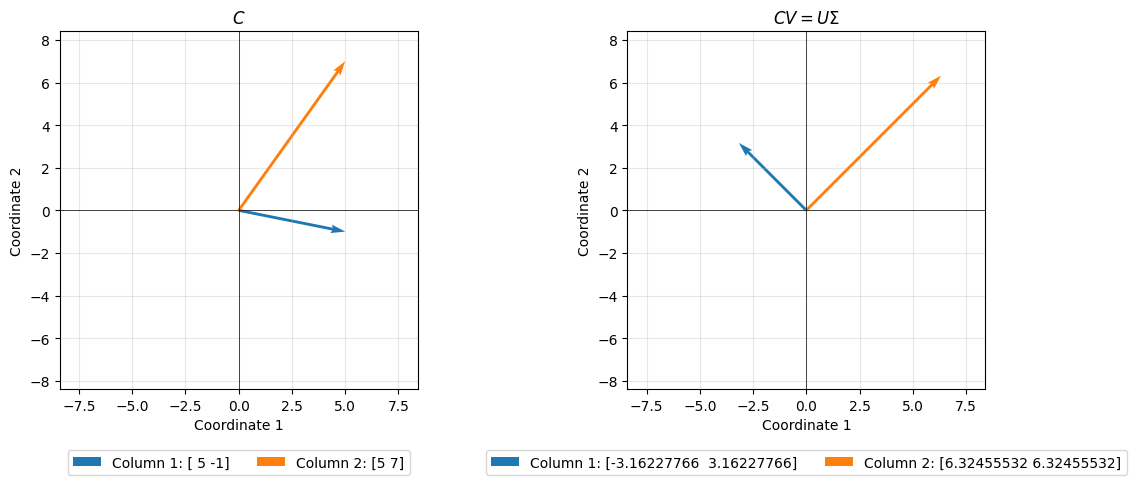

In [8]:
C_dot_V = C @ verified_unit_eigenvectors

limit = 1.2 * max(np.abs(C).max(), np.abs(C_dot_V).max(), 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_matrix_columns(C, axes[0], r"$C$", limit)
plot_matrix_columns(C_dot_V, axes[1], r"$CV = U\Sigma$", limit)
plt.tight_layout()
plt.show()

The resulting columns of $C V$ are perpendicular, with lengths equal to the singular values.

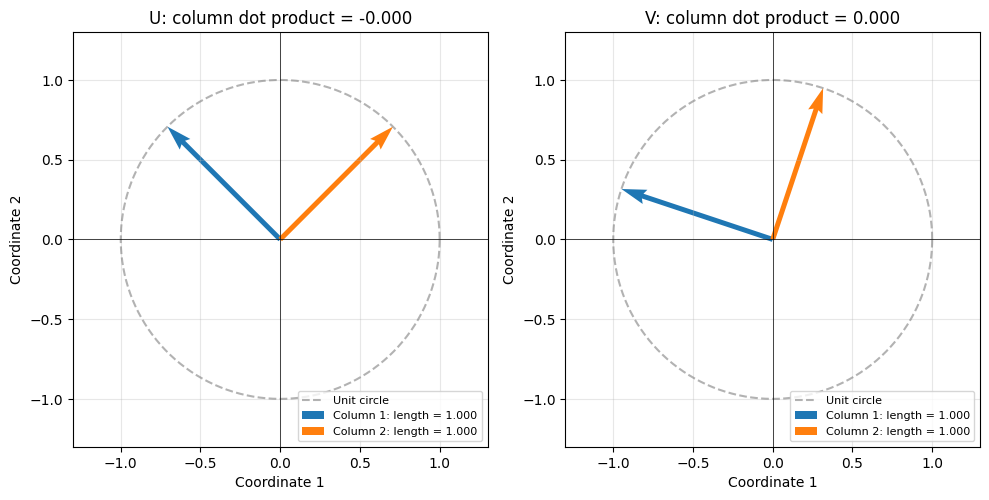

In [9]:
plot_orthonormality(U_from_C, verified_unit_eigenvectors)

### Sign ambiguity in singular vectors

Singular vectors are not unique in sign. A vector and its negative describe
the same axis, so both are valid:

$$
\begin{bmatrix}
-\frac{1}{\sqrt{2}}\\
\frac{1}{\sqrt{2}}
\end{bmatrix}
=
-
\begin{bmatrix}
\frac{1}{\sqrt{2}}\\
-\frac{1}{\sqrt{2}}
\end{bmatrix}.
$$

This explains why a manual calculation and NumPy SVD may produce columns
with opposite signs.

For the decomposition

$$
C = U\Sigma V^T,
$$

flipping the sign of a column of $U$ requires flipping the corresponding
column of $V$. The two sign changes cancel:

$$
\sigma_i(-u_i)(-v_i)^T = \sigma_i u_i v_i^T.
$$

Therefore, the singular values and reconstructed matrix remain unchanged.

**The signs do not need to match a reference solution.** What matters is
that the vectors are paired consistently and reconstruct the original matrix.

In [10]:
U_from_svd, singular_values, Vt = np.linalg.svd(C)
Sigma_from_svd = np.diag(singular_values)

display_matrix(U_from_svd, matrix_name="U", number_format=".3f")
display_matrix(Sigma_from_svd, matrix_name=r"\Sigma", number_format=".3f")
display_matrix(Vt.T, matrix_name="V", number_format=".3f")

# Verify that the decomposition reconstructs C.
print("Reconstruction matches C:", np.allclose(C, U_from_svd @ Sigma_from_svd @ Vt))
print("Reconstruction matches for singular values:", np.allclose(Sigma, Sigma_from_svd))
#print("Reconstruction matches for U before flipping:", np.allclose(U_from_C, U_from_svd))
#print("Reconstruction matches for U after flipping:", np.allclose(U_flipped, U_from_svd))

display(Markdown("### Original eigenvalues and eigenvectors"))

display_matrix(
    verified_eigenvalues.reshape(1, -1),
    matrix_name=r"\lambda_{\mathrm{original}}",
    number_format=".3f",
)
display_matrix(
    verified_unit_eigenvectors,
    matrix_name=r"V_{\mathrm{original}}",
    number_format=".3f",
)

display(Markdown("### 1. Match SVD's descending order"))
order = np.argsort(verified_eigenvalues)[::-1]
print("Column ordering (zero-based indices):", order)

eigenvalues_desc = verified_eigenvalues[order]
V = verified_unit_eigenvectors[:, order].copy()
Sigma = np.diag(np.sqrt(eigenvalues_desc))
U_from_C = (C @ V) / np.diag(Sigma)

display_matrix(
    eigenvalues_desc.reshape(1, -1),
    matrix_name=r"\lambda_{\mathrm{descending}}",
    number_format=".3f",
)
display_matrix(Sigma, matrix_name=r"\Sigma", number_format=".3f")
display_matrix(U_from_C, matrix_name=r"U_{\mathrm{reordered}}", number_format=".3f")
display_matrix(V, matrix_name=r"V_{\mathrm{reordered}}", number_format=".3f")

display(Markdown("### 2. Get the reference SVD"))
U_from_svd, _, Vt_from_svd = np.linalg.svd(C, full_matrices=False)
V_from_svd = Vt_from_svd.T

display_matrix(V_from_svd, matrix_name=r"V_{\mathrm{SVD}}", number_format=".3f")

display(Markdown("### 3. Align matching columns of U and V"))
signs = np.where(
    np.sum(U_from_C * U_from_svd, axis=0) < 0,
    -1.0,
    1.0,
)

U_flipped = U_from_C * signs
V_flipped = V * signs

print("Sign multipliers for each column:", signs)
display_matrix(U_flipped, matrix_name=r"U_{\mathrm{aligned}}", number_format=".3f")
display_matrix(V_flipped, matrix_name=r"V_{\mathrm{aligned}}", number_format=".3f")

print("U matches SVD:", np.allclose(U_flipped, U_from_svd))
print("V matches SVD:", np.allclose(V_flipped, V_from_svd))
print(
    "Reconstruction matches C:",
    np.allclose(C, U_flipped @ Sigma @ V_flipped.T),
)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Reconstruction matches C: True
Reconstruction matches for singular values: False


### Original eigenvalues and eigenvectors

<IPython.core.display.Math object>

... (10 outputs left out)

Sign multipliers for each column: [ 1. -1.]


<IPython.core.display.Math object>

<IPython.core.display.Math object>

U matches SVD: True
V matches SVD: True
Reconstruction matches C: True


### Verifying orthogonality and orthonormality of $U$ and $V$

**Orthogonal columns** are mutually perpendicular: the dot product of any
two distinct columns is zero.

**Orthonormal columns** are mutually perpendicular and each has unit length.

To check these properties, calculate:

$$
U^T U,\qquad V^T V.
$$

Each entry is a dot product between two columns:

- **Off-diagonal entries** are zero when distinct columns are orthogonal.
- **Diagonal entries** are the squared column lengths. They equal 1 when
  the columns have unit length.

Therefore, orthogonality requires these products to be diagonal matrices,
while orthonormality requires identity matrices:

$$
U^T U = I,\qquad V^T V = I.
$$

For our square SVD matrices, $U$ and $V$ are called **orthogonal
matrices**, meaning their columns are **orthonormal**.

In numerical calculations, check these equalities approximately to allow
for floating-point rounding.

In [11]:
U = U_flipped
V = V_flipped

display_matrix(U.T @ U, matrix_name=r"U^T U", number_format=".3f")
display_matrix(V.T @ V, matrix_name=r"V^T V", number_format=".3f")

print("U has orthonormal columns:",
      np.allclose(U.T @ U, np.eye(U.shape[1])))

print("V has orthonormal columns:",
      np.allclose(V.T @ V, np.eye(V.shape[1])))

def has_orthogonal_columns(matrix: np.ndarray) -> bool:
    # gram stores the dot product of the transposed matrix with itself
    gram = matrix.T @ matrix
    # off_diagonal stores the difference between gram and np.diag(np.diag(gram))
    # np.diag(np.diag(gram)) keeps the diagonal values of gram and sets everything else to zero.
    off_diagonal = gram - np.diag(np.diag(gram))
    return bool(np.allclose(off_diagonal, 0, atol=1e-10))

print("U columns are orthogonal:", has_orthogonal_columns(U))
print("V columns are orthogonal:", has_orthogonal_columns(V))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

U has orthonormal columns: True
V has orthonormal columns: True
U columns are orthogonal: True
V columns are orthogonal: True


### To calculate orthogonality

Transpose the first column, multiply it by the second column. Matrix multiplication then multiplies corresponding entries and sums them.
For columns $u_1$ and $u_2$:

$$
u_1=\begin{bmatrix}a\\b\end{bmatrix},
\qquad
u_2=\begin{bmatrix}c\\d\end{bmatrix}
$$
their dot product is:
$$
u_1^T u_2
=
\begin{bmatrix}a&b\end{bmatrix}
\begin{bmatrix}c\\d\end{bmatrix}
=ac+bd.
$$

Using your example:

$$
\begin{bmatrix}-\frac1{\sqrt2}&\frac1{\sqrt2}\end{bmatrix}
\begin{bmatrix}\frac1{\sqrt2}\\\frac1{\sqrt2}\end{bmatrix}
=
-\frac12+\frac12=0.
$$
The zero result means the columns are orthogonal.

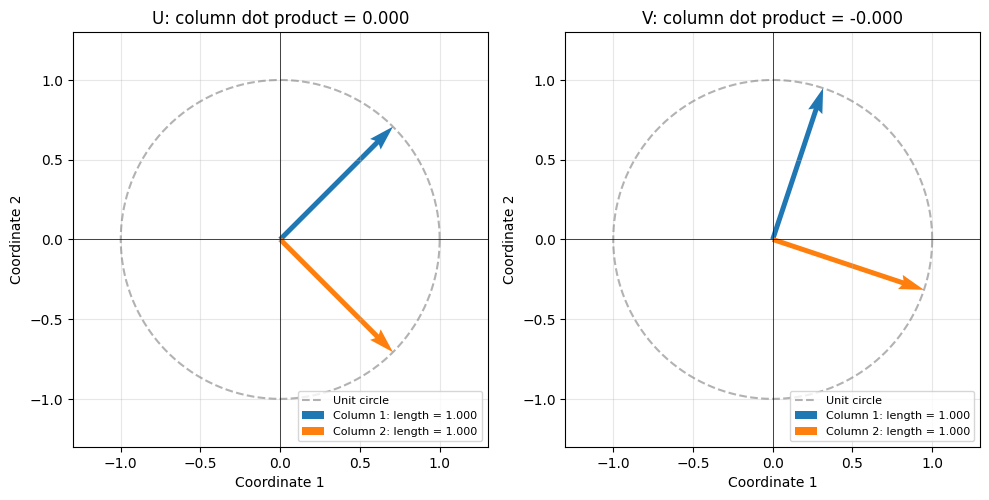

In [12]:
plot_orthonormality(U_flipped, V_flipped)